# Demo

- input -> model -> output si analzia erorilor

In [83]:
import pandas as pd
import re
from sklearn.preprocessing import StandardScaler, LabelEncoder
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
import torch.nn as nn
from transformers import AutoModel
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import f1_score, accuracy_score
import torch
import numpy as np
import random

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from collections import Counter
import unicodedata
import os

In [84]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device {device}")

Device cpu


### Demo1: Transformer stilo fusion

- clasele pt model si dataset si functiile auxiliare de clean

In [85]:
# FUNCTII UTILE le definim sus
def drop_columns(df, columns_to_drop):
    return df.drop(columns=columns_to_drop)

# avem o problema la moldova
# diacriticele aparent nu sunt unicode?
def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    text = unicodedata.normalize("NFC", text)

    # remove combining chars, deci t de la tap nu va mai avea caciulita sepaarata va fi un singur char
    text = ''.join(c for c in text if not unicodedata.combining(c))

    text = text.replace("„", '"').replace("”", '"')
    text = text.replace("’", "'")

    # remove control chars
    text = ''.join(c for c in text if unicodedata.category(c)[0] != 'C')

    text = text.replace("\n", " ")
    text = text.replace('""', '"')
    text = re.sub(r"\s+", " ", text)
        
    return text.strip()


def count_unk(texts, tokenizer, n=100):
    total_unk = 0
    total_tokens = 0

    for t in texts[:n]:
        enc = tokenizer(
            t,
            truncation=True,
            max_length=512
        )

        input_ids = enc["input_ids"]
        total_tokens += len(input_ids)

        unk_id = tokenizer.unk_token_id
        total_unk += sum(1 for x in input_ids if x == unk_id)

    return total_unk / total_tokens


def count_unk_absolute(texts, tokenizer, n=100):
    total_unk = 0
    for t in texts[:n]:
        enc = tokenizer(t, truncation=True, max_length=512)
        unk_id = tokenizer.unk_token_id
        total_unk += sum(1 for x in enc["input_ids"] if x == unk_id)
    return total_unk


def count_combining(texts, n=1000):
    count = 0
    for t in texts[:n]:
        if any(unicodedata.combining(c) for c in t):
            count += 1
    return count


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [86]:
STYLO_FEATURES = [
    # stylo basic
    'stylo_avg_word_length', 'stylo_std_word_length',
    'stylo_avg_sentence_length', 'stylo_std_sentence_length',
    'stylo_sentence_count', 'stylo_hapax_rate',
    'stylo_punctuation_rate', 'stylo_question_rate',
    'stylo_exclamation_rate', 'stylo_lexical_diversity',
    'stylo_noun_ratio', 'stylo_verb_ratio',
    'stylo_adj_ratio', 'stylo_adv_ratio',
    'stylo_pron_ratio', 'stylo_det_ratio',
    'stylo_aux_ratio',
    # advanced
    'adv_prep_rate', 'adv_conj_rate', 'adv_pron_rate',
    'adv_art_rate', 'adv_aux_rate', 'adv_transition_rate',
    'adv_word_repetition_rate', 'adv_flesch_ro',
    'adv_gunning_fog', 'adv_mttr', 'adv_mtld', 'adv_unique_bigram_rate',
    'adv_unique_trigram_rate', 'adv_diacritic_ratio',
    'adv_suffix_rate', 'adv_uppercase_words_rate'
]

In [87]:
tokenizer = AutoTokenizer.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")

In [88]:
class AuthorDatasetFusion(Dataset):
    def __init__(self, texts, labels, stylo_features, 
                 tokenizer, max_length=512, overlap=0.1):
        self.texts          = texts
        self.labels         = labels
        self.stylo_features = stylo_features  # numpy array
        self.tokenizer      = tokenizer
        self.max_length     = max_length
        self.stride         = int(max_length * (1 - overlap))
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text        = self.texts[idx]
        label       = self.labels[idx]
        stylo_feats = self.stylo_features[idx]
        
        encoded = self.tokenizer(
            text,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        
        return {
            'input_ids':      encoded['input_ids'].squeeze(0),
            'attention_mask': encoded['attention_mask'].squeeze(0),
            'stylo_features': torch.tensor(
                stylo_feats, dtype=torch.float32
            ),
            'label': torch.tensor(label, dtype=torch.long)
        }


DATALOADERELE!!

In [89]:
def build_dataloaders_fusion(train_df, val_df, test_df,
                              tokenizer, stylo_features_cols,
                              batch_size=8, seed=42):
    le = LabelEncoder()
    le.fit(train_df['author'])

    y_train = le.transform(train_df['author'])
    y_val   = le.transform(val_df['author'])
    y_test  = le.transform(test_df['author'])

    print(f"Autori: {le.classes_}")

    texts_train = train_df['text'].tolist()
    texts_val   = val_df['text'].tolist()
    texts_test  = test_df['text'].tolist()

    print("\n[DEBUG] Combining chars BEFORE clean:")
    print("Train combining:", count_combining(texts_train))
    print("Val   combining:", count_combining(texts_val))
    print("Test  combining:", count_combining(texts_test))

    texts_train = train_df['text'].apply(clean_text).tolist()
    texts_val   = val_df['text'].apply(clean_text).tolist()
    texts_test  = test_df['text'].apply(clean_text).tolist()

    print("\n[DEBUG] UNK check:")
    print("Train UNK:", count_unk_absolute(texts_train, tokenizer))
    print("Val   UNK:", count_unk_absolute(texts_val, tokenizer))
    print("Test  UNK:", count_unk_absolute(texts_test, tokenizer))

    print("\n[DEBUG] Combining chars AFTER clean:")
    print("Train combining:", count_combining(texts_train))
    print("Val   combining:", count_combining(texts_val))
    print("Test  combining:", count_combining(texts_test))
    

    scaler      = StandardScaler()
    X_train     = scaler.fit_transform(train_df[stylo_features_cols].fillna(0))
    X_val       = scaler.transform(val_df[stylo_features_cols].fillna(0))
    X_test      = scaler.transform(test_df[stylo_features_cols].fillna(0))

    train_ds = AuthorDatasetFusion(texts_train, y_train, X_train, tokenizer)
    val_ds   = AuthorDatasetFusion(texts_val,   y_val,   X_val,   tokenizer)
    test_ds  = AuthorDatasetFusion(texts_test,  y_test,  X_test,  tokenizer)

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(train_ds, batch_size=batch_size,
                              shuffle=True,  num_workers=4,
                              pin_memory=True, generator=generator)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size,
                              shuffle=False, num_workers=4, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size,
                              shuffle=False, num_workers=4, pin_memory=True)

    print(f"Autori: {len(le.classes_)} | Stylo features: {X_train.shape[1]}")

    return train_loader, val_loader, test_loader, le, texts_test, y_test, X_test


Clasa modelului

In [90]:
class BERTWithStylometry(nn.Module):
    # de ce folosim nn.Module?
    # pentru ca backbone la torch.nn
    # fiecare model din pytroch este de fapt o subclasa nn.Module
    # Module abstractizeaza deifinirea layerelor, forward si backward. Adica stie sa inmulteasca matrice pe scurt :)
    # si se ocupa si de parametrii , optimizator , scheduler, d-aia poti sa ii si salvezi usor
    def __init__(self, num_authors, no_stylo_features, dropout=0.2):
        super(BERTWithStylometry,self).__init__()
        # ok avem sablonul pe Module
        # ce componente avem? tokenizer (encoder bert), reteaua intermediara ('encoder' MLP) si reteaua finala (MLP)
        # 1. self.bert
        # 2. self.bert_dropout
        # 3. self.stylo_network
        # 4. self.fusion
        # 5. self.classifier
        self.bert = AutoModel.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")
        
        # ca la orice retea se aplica dropout dar vom diferentia de data asta pentru ca dropout rate va exista si la MLP
        # bert are deja un dropout intern la encoder dar asta al nostru se aplica doar pe embeddingul final adica CLS
        # teoretic nu e obligatoriu dar e good practice
        self.bert_dropout = nn.Dropout(dropout)

        # ok acum definim mlp pt fusion
        # trebuie concatenate? 
        # nu cred ca aici dar trb sa stim straturile si dropout
        # [semantic + stil] -> reprezentare combinata
        # in_dim: 768 (bert CLS) + 64 (Stilo MLP) = 832
        # folosim dropout de la CLS
        self.fusion = nn.Sequential(
            nn.Linear(768 + no_stylo_features, 256),
            nn.LayerNorm(256),   # - in loc de ReLU direct
            nn.GELU(),           # - GELU in loc de ReLU
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        # clasificatorul final 
        self.classifier = nn.Linear(128, num_authors)

    # ne uitam cum am definit inputul in Dataset
    # input id: textul cu tokeni cu embeddinguri
    # attention mask calculata de bert -> matrice binara deci un vector pt fiecare text?
    # 1 atentie pe acel token 0 il ignori
    # ambele au shape [B, L]  batch_size, max_length (512)
    # nu folosim labels aici , mai intai forward pass calculeaza scoruri brute (logits)
    # label = y este folosit in loss!
    def forward(self, input_ids, attention_mask, stylo_features):
        bert_output = self.bert(input_ids=input_ids,
                                attention_mask=attention_mask)
        
        # mean pooling in loc de CLS
        # pooled = mean_pooling(bert_output, attention_mask)  # (B, 768)
        pooled = bert_output.last_hidden_state[:, 0, :]  # (B, 768) - CLS token
        pooled = self.bert_dropout(pooled)
        
        # concatenare directa fara MLP intermediar
        concatenated = torch.cat([pooled, stylo_features], dim=1)  # (B, 803)
        
        fusion_output = self.fusion(concatenated)   # (B, 128)
        logits        = self.classifier(fusion_output)  # (B, num_authors)
        return logits
    


FUNCTIILE DE EVALUARE

In [91]:
def predict_with_voting_fusion(model, text, stylo_vector, tokenizer, device, max_length=512, overlap=0.1):
    # text lung > 512 token?
    # il impartim in ferestre de 512 token
    # stride = 512 * (1 - 0.1) ≈ 460 
    #[0:512] , [460:972], [920:1432]
    stride = int(max_length * (1 - overlap))
    model.eval()

    # nu truncam textul il vrem pe tot aici 
    tokens = tokenizer(text, truncation=False, add_special_tokens=True, return_tensors='pt')
    # scoatem tokenii
    input_ids = tokens['input_ids'][0]
    
    # scoatem tensor din stylo features deci folosim unsqueeze ->(1, L)
    stylo_tensor =torch.tensor(
        stylo_vector, dtype=torch.float32
    ).unsqueeze(0).to(device)
    predictions =[]

    with torch.no_grad():
        # parcurgem textul pe ferestre
        for start in range(0, len(input_ids), stride):
            # luam fereastra curenta, avem grija ca poate sa fie mai mica ca 512
            end = min(start + max_length, len(input_ids))
            window = input_ids[start:end]

            # padding in caz ca e mai mica, de la len(window) -> 512 
            if len(window) < max_length:
                padding = torch.zeros(max_length - len(window), dtype=torch.long)
                # concatenam
                window = torch.cat([window, padding])
            
            # punem 1 doar pe tokenii nepadati adica cei diferiti de 0
            attn_mask = (window != 0).long()

            # cum integram si stilometria?
            # stilometria e calculata pe intreg documentul 
            # deci am acelasi vector pt toate ferestrele
            logits = model(
                window.unsqueeze(0).to(device),
                attn_mask.unsqueeze(0).to(device),
                stylo_tensor
            )

            pred = torch.argmax(logits, dim=-1).item()
            predictions.append(pred)

            if end == len(input_ids):
                break # gata secventa
    # scoatem cea mai frecventa predictie 
    # Counter returneaza un dictionar cu key = predictia , val = de cate ori apare predictia
    counter_dict = Counter(predictions)
    return counter_dict.most_common(1)[0][0]
        

def evaluate_with_voting(texts, y_true, X_stylo, tokenizer, label_encoder, device, dataset_name="", model_path=None):

    num_authors = len(np.unique(y_true))
    num_stylo_features = X_stylo.shape[1]
    
    model = BERTWithStylometry(
        num_authors=num_authors, 
        no_stylo_features=num_stylo_features
    ).to(device)

    
    if model_path is not None:
        model.load_state_dict(torch.load(model_path, map_location=device))
        print(f"Incarcat best model din {model_path}")

    print(f"\nEvaluare fusion cu majority voting — {dataset_name}")

    all_preds = []
    for i, (text, stylo_vec) in enumerate(zip(texts, X_stylo)):
        pred = predict_with_voting_fusion(
            model, text, stylo_vec, tokenizer, device
        )
        all_preds.append(pred)
        if i % 100 == 0:
            print(f"  {i}/{len(texts)}")

    f1  = f1_score(y_true, all_preds, average='macro')
    acc = (np.array(all_preds) == np.array(y_true)).mean()

    print(f"\nTest F1 macro: {f1:.4f} | Accuracy: {acc:.4f}")
    print(classification_report(
        y_true, all_preds,
        target_names=label_encoder.classes_
    ))

    return all_preds, f1, acc

Matriciel de confuzie (o pun pe aia normala nu normlized!!)

In [92]:
def plot_confusion_matrix_bert_fusion(y_true, y_pred, label_encoder,
                              dataset_name="", split='test'):

    labels = label_encoder.classes_
    n = len(labels)

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig_size = max(12, n * 0.8)

    font_size = max(6, int(300 / n))

    # === COUNTS ===
    plt.figure(figsize=(fig_size, fig_size))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": font_size},
        square=True,
        cbar=True
    )

    plt.title(f'Confusion Matrix (Counts) — {dataset_name} | {split}', fontsize=16)
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)

    plt.tight_layout()
    plt.savefig(f'cm_counts_fusion_{dataset_name}_{split}.png', dpi=150, bbox_inches='tight')
    plt.show()


Avem deja salvate features stilometrice impreuna cu textele lor in fisierele din care vom citi

#### Top 20 ro

In [93]:
model_path_fusion_ro20 = "best_model_fusion_top20_ro.pt"

In [94]:
# citim
top20_ro_train_text = pd.read_csv('final_stilo/top20_ro_train.csv')
top20_ro_val_text = pd.read_csv('final_stilo/top20_ro_val.csv')
top20_ro_test_text = pd.read_csv('final_stilo/top20_ro_test.csv')

Ok nu facem pe toti ca dureaza dar putem selecta un subset decent si sa vedem ce se intampla acolo

In [95]:
# apelam data loaderele
train_loader_ro20, val_loader_ro20, test_loader_ro20, label_encoder, texts_test, y_test, X_test = build_dataloaders_fusion(
    top20_ro_train_text, top20_ro_val_text, top20_ro_test_text,
    tokenizer, STYLO_FEATURES, batch_size=8
)

Autori: ['Adrian Dumitru' 'Alexandra Andronie' 'Alexandru Costea'
 'Alexandru Toader' 'Alina Manaila' 'Alina Popescu' 'Andrada Giubega'
 'Andreea Tobias' 'Bogdan Pacurar' 'Daniela Chihaia' 'Diana Nechita'
 'Georgiana Marina' 'Ioana Coman' 'Liviu Cojan' 'Luana Pavaluca'
 'Marco Badea' 'Mihnea Lazar' 'Monica Bonea' 'Robert Kiss'
 'Vlad Mironescu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 1
Val   combining: 1
Test  combining: 2

[DEBUG] UNK check:
Train UNK: 3
Val   UNK: 5
Test  UNK: 0

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0
Autori: 20 | Stylo features: 33


In [96]:
#selectam indices pentru demo
# alegem primele 3 texte din primii 10 autori

demo_indices = []
for autor in label_encoder.classes_[:20]:  # primii 20 autori
    autor_idx = label_encoder.transform([autor])[0]
    # gasim pozitiile din y_test unde apare autorul
    positions = [i for i, y in enumerate(y_test) if y == autor_idx]
    demo_indices.extend(positions[:3])  # primele 3 texte

print(f"Texte demo: {len(demo_indices)}")

Texte demo: 60


In [97]:
texts_demo = [texts_test[i] for i in demo_indices]
y_demo     = [y_test[i]     for i in demo_indices]
X_demo     = X_test[demo_indices]  # numpy indexing direct

Grafice stilo

In [98]:
demo_df_info = pd.DataFrame({
    'Autor': [label_encoder.classes_[y] for y in y_demo],
})
print("=== Autori selectati pt demo ===")
display(demo_df_info['Autor'].value_counts().reset_index().rename(
    columns={'index': 'Autor', 'Autor': 'Nr texte'}
))

=== Autori selectati pt demo ===


,Nr texte,count
0,Adrian Dumitru,3
1,Alexandra Andronie,3
2,Alexandru Costea,3
3,Alexandru Toader,3
4,Alina Manaila,3
5,Alina Popescu,3
6,Andrada Giubega,3
7,Andreea Tobias,3
8,Bogdan Pacurar,3
9,Daniela Chihaia,3


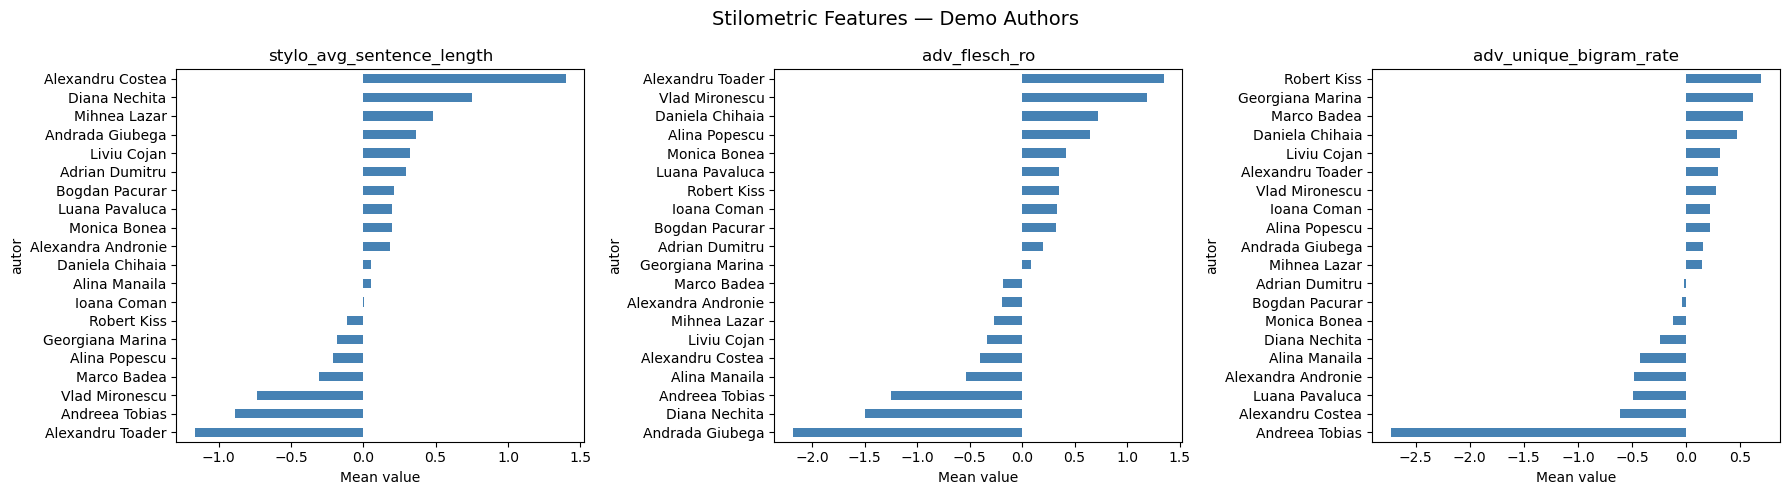

In [99]:
# 2. Distributia unui feature stilometric per autor
features_de_afisat = [
    'stylo_avg_sentence_length',
    'adv_flesch_ro', 
    'adv_unique_bigram_rate'
]

autori_demo_names = [label_encoder.classes_[y] for y in y_demo]

demo_stylo_df = pd.DataFrame(
    X_demo, 
    columns=STYLO_FEATURES
)
demo_stylo_df['autor'] = autori_demo_names

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Stilometric Features — Demo Authors', fontsize=14)

for ax, feat in zip(axes, features_de_afisat):
    demo_stylo_df.groupby('autor')[feat].mean().sort_values().plot(
        kind='barh', ax=ax, color='steelblue'
    )
    ax.set_title(feat)
    ax.set_xlabel('Mean value')

plt.tight_layout()
plt.show()

Aratam cat de diferit e autorul fata de medie, folosind z score al featerureurilor stilometrice pentru a vedea deplasarea fata de medie a fiecarui autor. Media este 0 pentru ca am scalat cu StandardScaler() in `build_data_loaders`.

$$\mathbf{z_{score} = \frac{x - \mu_{train}}{\sigma_{train}}}$$

- `z = 0` inseamna ca autorul e la media tuturor autorilor din train
- `z < 0` autorul e deasupra mediei
- `z > 0` autorul e sub medie.


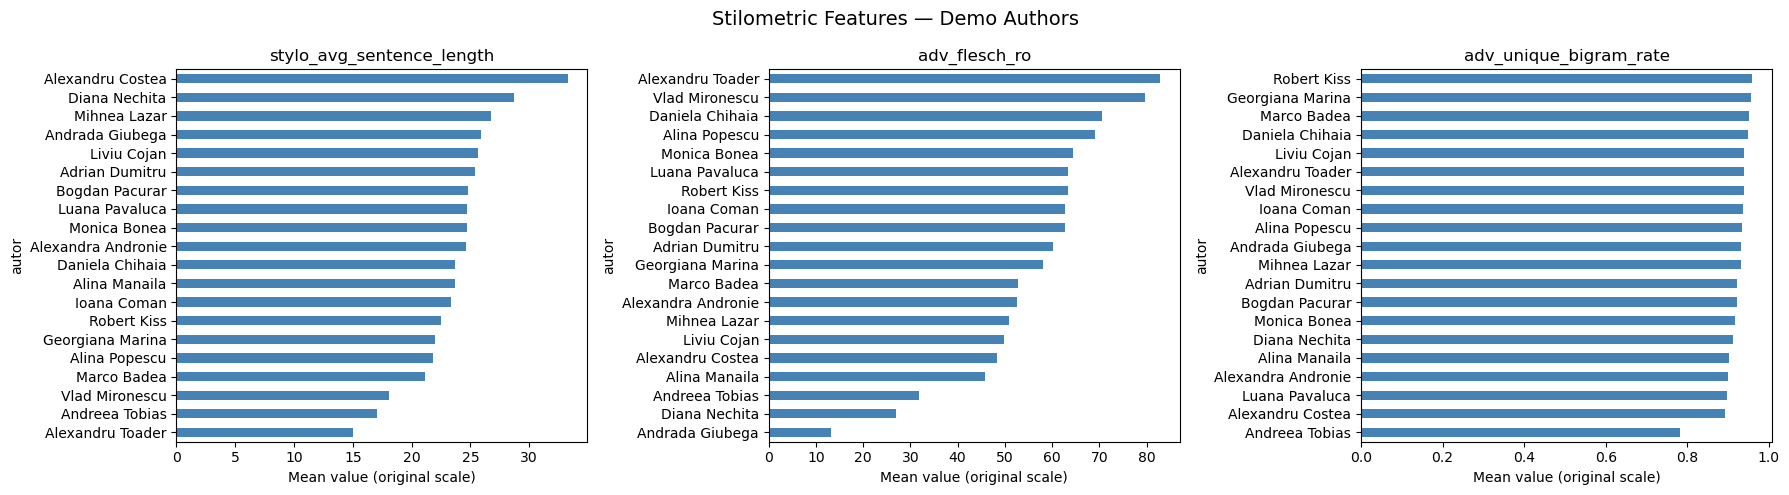

In [100]:
demo_stylo_df_raw = top20_ro_test_text.iloc[demo_indices][STYLO_FEATURES].copy()
demo_stylo_df_raw['autor'] = autori_demo_names

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Stilometric Features — Demo Authors', fontsize=14)

for ax, feat in zip(axes, features_de_afisat):
    demo_stylo_df_raw.groupby('autor')[feat].mean().sort_values().plot(
        kind='barh', ax=ax, color='steelblue'
    )
    ax.set_title(feat)
    ax.set_xlabel('Mean value (original scale)')

plt.tight_layout()
plt.show()

Aici am prezentat si valorile absolute pentru usurinta citirii dar mai informative sunt cele din graficele anterioare

In [101]:
#incarc modelul
model_demo = BERTWithStylometry(
    num_authors=len(label_encoder.classes_),
    no_stylo_features=len(STYLO_FEATURES)
).to(device)

model_demo.load_state_dict(
    torch.load(model_path_fusion_ro20, map_location=device)
)
model_demo.eval()
print("Model incarcat!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat!


In [102]:
# predictii
results = []
for i, (text, true_label, stylo_vec) in enumerate(
    zip(texts_demo, y_demo, X_demo)
):
    pred = predict_with_voting_fusion(
        model_demo, text, stylo_vec, tokenizer, device
    )
    results.append({
        'Autor real':   label_encoder.classes_[true_label],
        'Autor prezis': label_encoder.classes_[pred],
        'Corect':       '✅' if pred == true_label else '❌',
        'Text preview': text[:100] + '...'
    })
    print(f"  {i+1}/{len(texts_demo)}")

df_results = pd.DataFrame(results)
display(df_results)
# 1 minut

  1/60
  2/60
  3/60
  4/60
  5/60
  6/60
  7/60
  8/60
  9/60
  10/60
  11/60
  12/60
  13/60
  14/60
  15/60
  16/60
  17/60
  18/60
  19/60
  20/60
  21/60
  22/60
  23/60
  24/60
  25/60
  26/60
  27/60
  28/60
  29/60
  30/60
  31/60
  32/60
  33/60
  34/60
  35/60
  36/60
  37/60
  38/60
  39/60
  40/60
  41/60
  42/60
  43/60
  44/60
  45/60
  46/60
  47/60
  48/60
  49/60
  50/60
  51/60
  52/60
  53/60
  54/60
  55/60
  56/60
  57/60
  58/60
  59/60
  60/60


,Autor real,Autor prezis,Corect,Text preview
0,Adrian Dumitru,Adrian Dumitru,✅,Cercetătorul Tamas Kiss spune că toate societă...
1,Adrian Dumitru,Adrian Dumitru,✅,"""În lumina ultimelor studii științifice, efica..."
2,Adrian Dumitru,Adrian Dumitru,✅,Localizat în interiorul sediului CIA din Langl...
3,Alexandra Andronie,Marco Badea,❌,"""Premierul de centru-dreapta al României a dem..."
4,Alexandra Andronie,Alina Popescu,❌,Poliția din Slovacia a dezvăluit că bărbatul d...
5,Alexandra Andronie,Monica Bonea,❌,"""Poșta Română va distribui voucherele sociale ..."
6,Alexandru Costea,Georgiana Marina,❌,În ceea ce privește soluțiile oferite de bănci...
7,Alexandru Costea,Alexandru Costea,✅,"""România se bucură de toate garanțiile de secu..."
8,Alexandru Costea,Luana Pavaluca,❌,"Microsatelitul NASA, denumit CAPSTONE (Cisluna..."
9,Alexandru Toader,Alexandru Toader,✅,Meteorologii anunță că vremea se va încălzi în...


In [103]:
# erori
erori  = df_results[df_results['Corect'] == '❌']
corecte = df_results[df_results['Corect'] == '✅']

print(f"Corecte: {len(corecte)}/{len(df_results)}")
print(f"Erori:   {len(erori)}/{len(df_results)}")
print(f"Acuratete demo: {len(corecte)/len(df_results):.1%}")

display(erori[['Autor real', 'Autor prezis', 'Text preview']])

Corecte: 40/60
Erori:   20/60
Acuratete demo: 66.7%


,Autor real,Autor prezis,Text preview
3,Alexandra Andronie,Marco Badea,"""Premierul de centru-dreapta al României a dem..."
4,Alexandra Andronie,Alina Popescu,Poliția din Slovacia a dezvăluit că bărbatul d...
5,Alexandra Andronie,Monica Bonea,"""Poșta Română va distribui voucherele sociale ..."
6,Alexandru Costea,Georgiana Marina,În ceea ce privește soluțiile oferite de bănci...
8,Alexandru Costea,Luana Pavaluca,"Microsatelitul NASA, denumit CAPSTONE (Cisluna..."
12,Alina Manaila,Diana Nechita,"Țările G7 (Marea Britanie, Germania, Italia, C..."
13,Alina Manaila,Liviu Cojan,"61 de arestări în Paris, din Place de la Conco..."
17,Alina Popescu,Luana Pavaluca,ACTUALIZARE ORA 18:00 Bilanțul exploziei de la...
28,Daniela Chihaia,Luana Pavaluca,Imagini cu puternic impact emoțional: În imagi...
34,Georgiana Marina,Luana Pavaluca,Marina turcă a avertizat într-un mesaj pe sist...


In [104]:
y_true_demo = y_demo
y_pred_demo = [label_encoder.transform([r['Autor prezis']])[0] 
               for r in results]

acc = accuracy_score(y_true_demo, y_pred_demo)
f1  = f1_score(y_true_demo, y_pred_demo, average='macro')

print(f"Accuracy demo:  {acc:.2%}")
print(f"F1 Macro demo:  {f1:.4f}")
print()
print(classification_report(
    y_true_demo, y_pred_demo,
    target_names=label_encoder.classes_[:20],
    zero_division=0
))

Accuracy demo:  66.67%
F1 Macro demo:  0.6473

                    precision    recall  f1-score   support

    Adrian Dumitru       1.00      1.00      1.00         3
Alexandra Andronie       0.00      0.00      0.00         3
  Alexandru Costea       1.00      0.33      0.50         3
  Alexandru Toader       1.00      1.00      1.00         3
     Alina Manaila       0.50      0.33      0.40         3
     Alina Popescu       0.67      0.67      0.67         3
   Andrada Giubega       1.00      1.00      1.00         3
    Andreea Tobias       1.00      1.00      1.00         3
    Bogdan Pacurar       0.75      1.00      0.86         3
   Daniela Chihaia       0.67      0.67      0.67         3
     Diana Nechita       0.75      1.00      0.86         3
  Georgiana Marina       0.50      0.67      0.57         3
       Ioana Coman       0.50      0.67      0.57         3
       Liviu Cojan       0.67      0.67      0.67         3
    Luana Pavaluca       0.17      0.33      0.22   

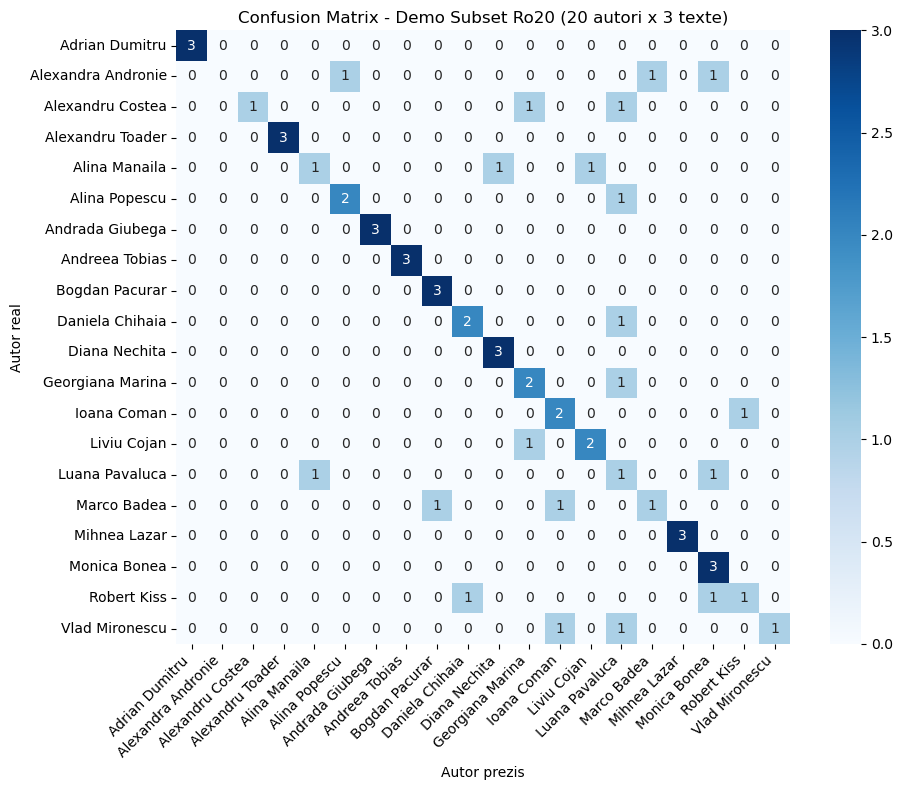

In [105]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

autori_selectati = [label_encoder.classes_[i] 
                    for i in sorted(set(y_true_demo))]

cm = confusion_matrix(y_true_demo, y_pred_demo)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=autori_selectati,
    yticklabels=autori_selectati,
    square=True
)
plt.title('Confusion Matrix - Demo Subset Ro20 (20 autori x 3 texte)')
plt.xlabel('Autor prezis')
plt.ylabel('Autor real')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

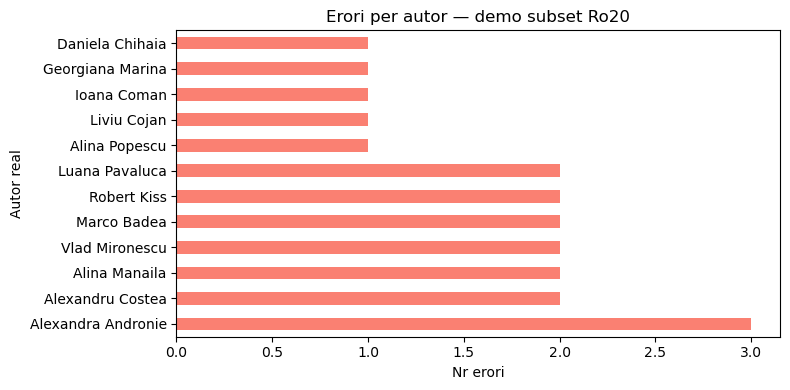

In [106]:
# care autori au cele mai multe erori
erori_per_autor = df_results[df_results['Corect'] == '❌']['Autor real'].value_counts()
erori_per_autor.plot(kind='barh', color='salmon', figsize=(8,4))
plt.title('Erori per autor — demo subset Ro20')
plt.xlabel('Nr erori')
plt.tight_layout()
plt.show()

#### Moldova top 20

In [107]:
model_path_fusion_mo20 = "best_model_fusion_top20_mo.pt"

In [108]:
# citim
top20_mo_train = pd.read_csv('final_stilo/top20_mo_train.csv')
top20_mo_val = pd.read_csv('final_stilo/top20_mo_val.csv')
top20_mo_test = pd.read_csv('final_stilo/top20_mo_test.csv')

In [109]:
# data loadere
train_loader_mo20, val_loader_mo20, test_loader_mo20, label_encoder_mo, texts_test_mo, y_test_mo, X_test_mo = build_dataloaders_fusion(
    top20_mo_train, top20_mo_val, top20_mo_test,
    tokenizer, STYLO_FEATURES, batch_size=8
)

Autori: ['Aliona Ciurca' 'Ana-Maria Dolghii' 'Cristian Sava' 'Cristina Dulea'
 'Cristina Mirca' 'Cristina Popescu' 'Diana Gatcan' 'Diana Severin'
 'Ecaterina Arvintii' 'Malvina Cojocari' 'Marina Ciobanu' 'Maxim Stratan'
 'Mihaela Conovali' 'Milena Onisim' 'Nicoleta Braghis' 'Stela Untila'
 'Svetlana Cartin' 'Svetlana Cojocaru' 'Valentina Buza' 'Viorica Rusu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 343
Val   combining: 422
Test  combining: 366

[DEBUG] UNK check:
Train UNK: 43
Val   UNK: 33
Test  UNK: 53

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0
Autori: 20 | Stylo features: 33


In [62]:
# selectez indices pentru demo
# alegem primele 3 texte din primii 10 autori

demo_indices = []
for autor in label_encoder_mo.classes_[:20]:  # primii 20 autori
    autor_idx = label_encoder_mo.transform([autor])[0]
    # gasim pozitiile din y_test unde apare autorul
    positions = [i for i, y in enumerate(y_test_mo) if y == autor_idx]
    demo_indices.extend(positions[:3])  # primele 3 texte

print(f"Texte demo: {len(demo_indices)}")

Texte demo: 60


In [63]:
# extrag subset din ce am deja
texts_demo = [texts_test_mo[i] for i in demo_indices]
y_demo     = [y_test_mo[i]     for i in demo_indices]
X_demo     = X_test_mo[demo_indices]  # numpy indexing direct

In [64]:
demo_df_info = pd.DataFrame({
    'Autor': [label_encoder_mo.classes_[y] for y in y_demo],
})
print("=== Autori selectati pt demo ===")
display(demo_df_info['Autor'].value_counts().reset_index().rename(
    columns={'index': 'Autor', 'Autor': 'Nr texte'}
))

=== Autori selectati pt demo ===


,Nr texte,count
0,Aliona Ciurca,3
1,Ana-Maria Dolghii,3
2,Cristian Sava,3
3,Cristina Dulea,3
4,Cristina Mirca,3
5,Cristina Popescu,3
6,Diana Gatcan,3
7,Diana Severin,3
8,Ecaterina Arvintii,3
9,Malvina Cojocari,3


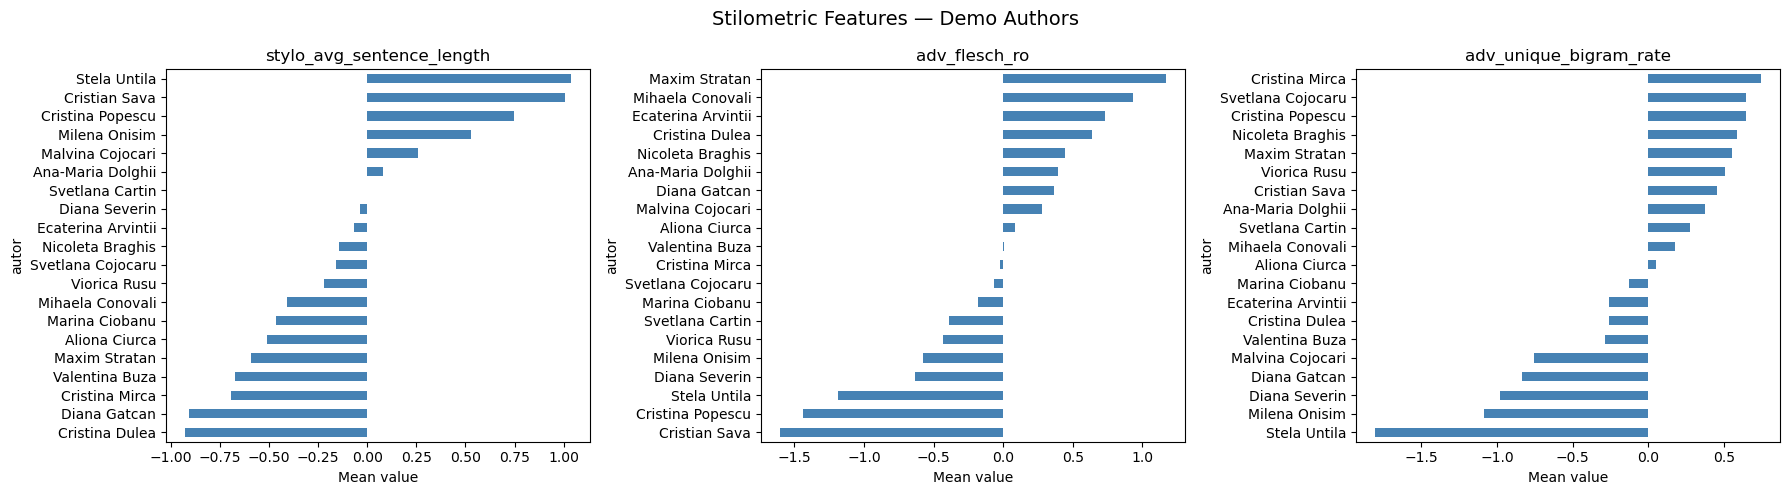

In [65]:
# distributia unui feature stilometric per autor
features_de_afisat = [
    'stylo_avg_sentence_length',
    'adv_flesch_ro', 
    'adv_unique_bigram_rate'
]

autori_demo_names = [label_encoder_mo.classes_[y] for y in y_demo]

demo_stylo_df = pd.DataFrame(
    X_demo, 
    columns=STYLO_FEATURES
)
demo_stylo_df['autor'] = autori_demo_names

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Stilometric Features — Demo Authors', fontsize=14)

for ax, feat in zip(axes, features_de_afisat):
    demo_stylo_df.groupby('autor')[feat].mean().sort_values().plot(
        kind='barh', ax=ax, color='steelblue'
    )
    ax.set_title(feat)
    ax.set_xlabel('Mean value')

plt.tight_layout()
plt.show()

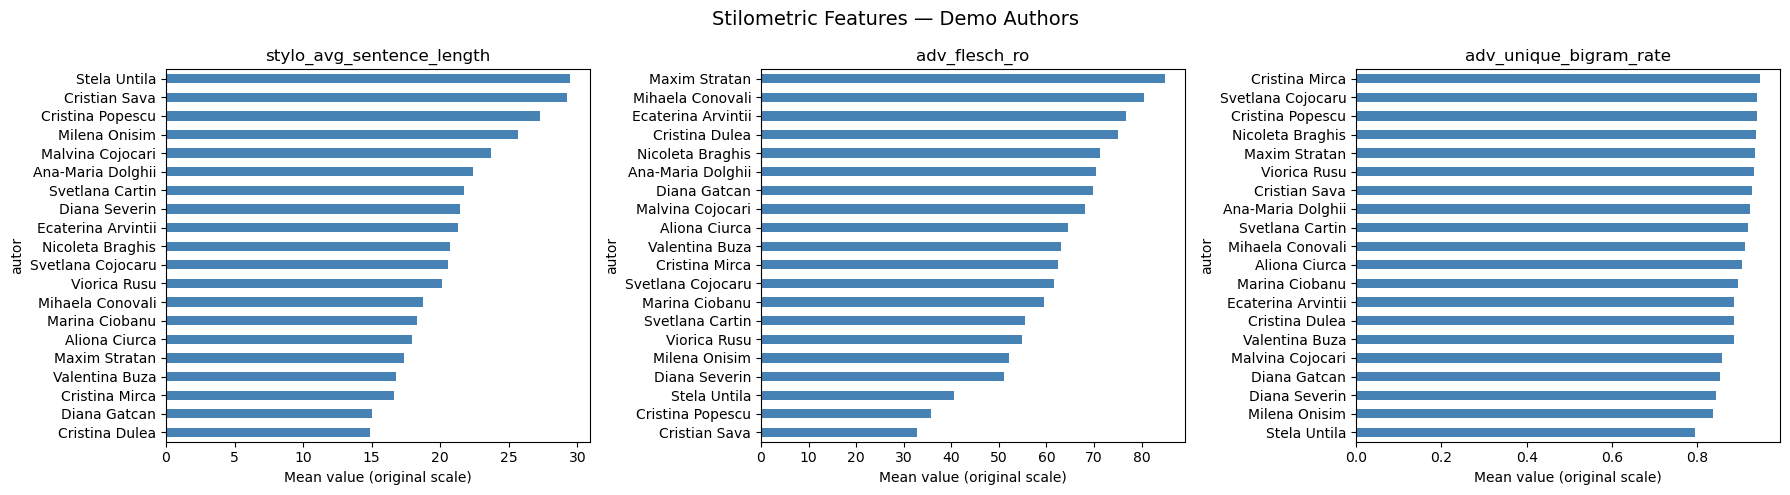

In [66]:
demo_stylo_df_raw = top20_mo_test.iloc[demo_indices][STYLO_FEATURES].copy()
demo_stylo_df_raw['autor'] = autori_demo_names

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Stilometric Features — Demo Authors', fontsize=14)

for ax, feat in zip(axes, features_de_afisat):
    demo_stylo_df_raw.groupby('autor')[feat].mean().sort_values().plot(
        kind='barh', ax=ax, color='steelblue'
    )
    ax.set_title(feat)
    ax.set_xlabel('Mean value (original scale)')

plt.tight_layout()
plt.show()

In [67]:
# incarcam modelul
model_demo = BERTWithStylometry(
    num_authors=len(label_encoder_mo.classes_),
    no_stylo_features=len(STYLO_FEATURES)
).to(device)

model_demo.load_state_dict(
    torch.load(model_path_fusion_mo20, map_location=device)
)
model_demo.eval()
print("Model incarcat!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model incarcat!


In [68]:
# predictii
results = []
for i, (text, true_label, stylo_vec) in enumerate(
    zip(texts_demo, y_demo, X_demo)
):
    pred = predict_with_voting_fusion(
        model_demo, text, stylo_vec, tokenizer, device
    )
    results.append({
        'Autor real':   label_encoder_mo.classes_[true_label],
        'Autor prezis': label_encoder_mo.classes_[pred],
        'Corect':       '✅' if pred == true_label else '❌',
        'Text preview': text[:100] + '...'
    })
    print(f"  {i+1}/{len(texts_demo)}")

df_results = pd.DataFrame(results)
display(df_results)
# 1 minut

  1/60
  2/60
  3/60
  4/60
  5/60
  6/60
  7/60
  8/60
  9/60
  10/60
  11/60
  12/60
  13/60
  14/60
  15/60
  16/60
  17/60
  18/60
  19/60
  20/60
  21/60
  22/60
  23/60
  24/60
  25/60
  26/60
  27/60
  28/60
  29/60
  30/60
  31/60
  32/60
  33/60
  34/60
  35/60
  36/60
  37/60
  38/60
  39/60
  40/60
  41/60
  42/60
  43/60
  44/60
  45/60
  46/60
  47/60
  48/60
  49/60
  50/60
  51/60
  52/60
  53/60
  54/60
  55/60
  56/60
  57/60
  58/60
  59/60
  60/60


,Autor real,Autor prezis,Corect,Text preview
0,Aliona Ciurca,Aliona Ciurca,✅,"Dumitru Braghiș, ambasadorul R. Moldova la Mos..."
1,Aliona Ciurca,Marina Ciobanu,❌,Trei polițiști din cadrul Direcției investigar...
2,Aliona Ciurca,Diana Gatcan,❌,Partidul Liberal (PL) urmează să prezinte o se...
3,Ana-Maria Dolghii,Ecaterina Arvintii,❌,"""Discutând despre stadiul procesului de negoci..."
4,Ana-Maria Dolghii,Stela Untila,❌,"Pe 2 iunie, la scurt timp după ce Canada a anu..."
5,Ana-Maria Dolghii,Malvina Cojocari,❌,Curtea de Apel Chișinău a respins argumentele ...
6,Cristian Sava,Cristian Sava,✅,"Conform proiectului, toate băncile din Republi..."
7,Cristian Sava,Svetlana Cojocaru,❌,Schema infracțională de legalizare a construcț...
8,Cristian Sava,Cristian Sava,✅,"SA ""Apă-Canal Chișinău"" precizează că furnizar..."
9,Cristina Dulea,Diana Severin,❌,"Fritz von Weizsäcker, fiul fostului președinte..."


In [69]:
# erori
erori  = df_results[df_results['Corect'] == '❌']
corecte = df_results[df_results['Corect'] == '✅']

print(f"Corecte: {len(corecte)}/{len(df_results)}")
print(f"Erori:   {len(erori)}/{len(df_results)}")
print(f"Acuratete demo: {len(corecte)/len(df_results):.1%}")

display(erori[['Autor real', 'Autor prezis', 'Text preview']])

Corecte: 39/60
Erori:   21/60
Acuratete demo: 65.0%


,Autor real,Autor prezis,Text preview
1,Aliona Ciurca,Marina Ciobanu,Trei polițiști din cadrul Direcției investigar...
2,Aliona Ciurca,Diana Gatcan,Partidul Liberal (PL) urmează să prezinte o se...
3,Ana-Maria Dolghii,Ecaterina Arvintii,"""Discutând despre stadiul procesului de negoci..."
4,Ana-Maria Dolghii,Stela Untila,"Pe 2 iunie, la scurt timp după ce Canada a anu..."
5,Ana-Maria Dolghii,Malvina Cojocari,Curtea de Apel Chișinău a respins argumentele ...
7,Cristian Sava,Svetlana Cojocaru,Schema infracțională de legalizare a construcț...
9,Cristina Dulea,Diana Severin,"Fritz von Weizsäcker, fiul fostului președinte..."
10,Cristina Dulea,Nicoleta Braghis,"Veniturile totale ale bugetului de stat, în 10..."
12,Cristina Mirca,Cristina Popescu,Teal House este o comunitate cu focus pe dezvo...
15,Cristina Popescu,Svetlana Cartin,Ștefan Gligor spune că trecerea candidaților l...


In [70]:
y_true_demo = y_demo
y_pred_demo = [label_encoder_mo.transform([r['Autor prezis']])[0] 
               for r in results]

acc = accuracy_score(y_true_demo, y_pred_demo)
f1  = f1_score(y_true_demo, y_pred_demo, average='macro')

print(f"Accuracy demo:  {acc:.2%}")
print(f"F1 Macro demo:  {f1:.4f}")
print()
print(classification_report(
    y_true_demo, y_pred_demo,
    target_names=label_encoder_mo.classes_[:20],
    zero_division=0
))

Accuracy demo:  65.00%
F1 Macro demo:  0.6267

                    precision    recall  f1-score   support

     Aliona Ciurca       1.00      0.33      0.50         3
 Ana-Maria Dolghii       0.00      0.00      0.00         3
     Cristian Sava       1.00      0.67      0.80         3
    Cristina Dulea       0.50      0.33      0.40         3
    Cristina Mirca       1.00      0.67      0.80         3
  Cristina Popescu       0.00      0.00      0.00         3
      Diana Gatcan       0.67      0.67      0.67         3
     Diana Severin       0.67      0.67      0.67         3
Ecaterina Arvintii       0.67      0.67      0.67         3
  Malvina Cojocari       0.75      1.00      0.86         3
    Marina Ciobanu       0.50      0.67      0.57         3
     Maxim Stratan       1.00      1.00      1.00         3
  Mihaela Conovali       1.00      0.67      0.80         3
     Milena Onisim       1.00      1.00      1.00         3
  Nicoleta Braghis       0.60      1.00      0.75   

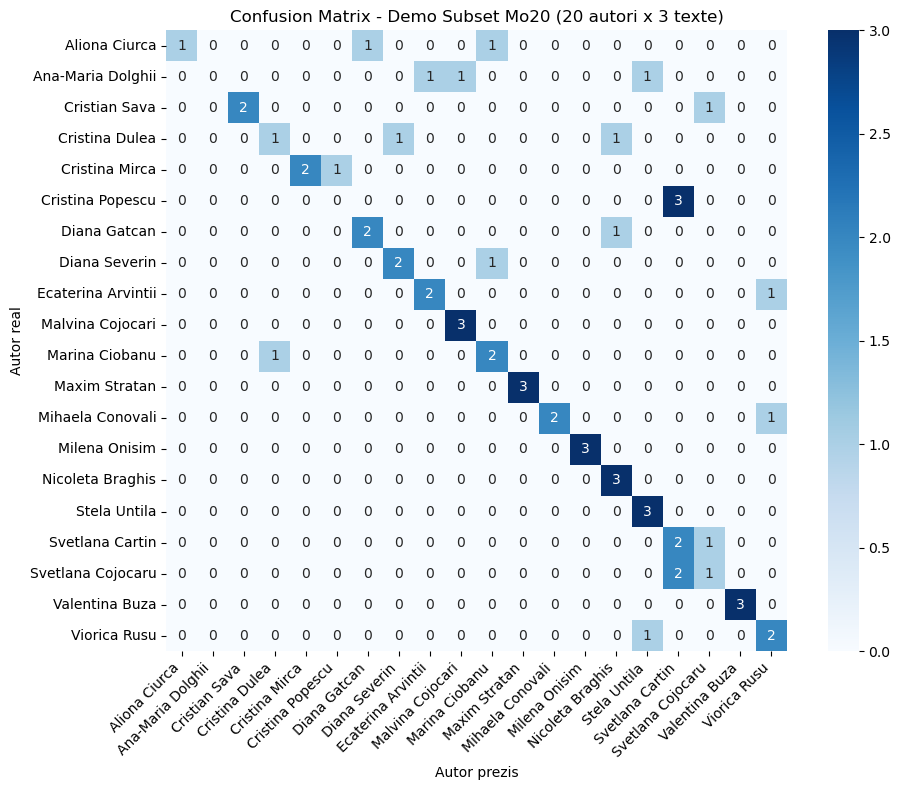

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

autori_selectati = [label_encoder_mo.classes_[i] 
                    for i in sorted(set(y_true_demo))]

cm = confusion_matrix(y_true_demo, y_pred_demo)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=autori_selectati,
    yticklabels=autori_selectati,
    square=True
)
plt.title('Confusion Matrix - Demo Subset Mo20 (20 autori x 3 texte)')
plt.xlabel('Autor prezis')
plt.ylabel('Autor real')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

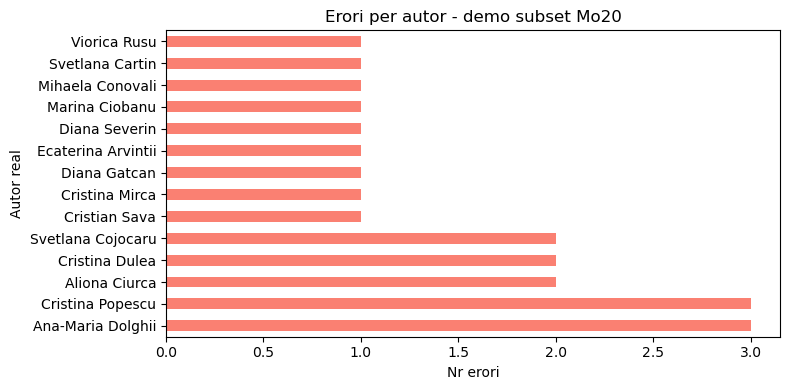

In [39]:
# care autori au cele mai multe erori
erori_per_autor = df_results[df_results['Corect'] == '❌']['Autor real'].value_counts()
erori_per_autor.plot(kind='barh', color='salmon', figsize=(8,4))
plt.title('Erori per autor - demo subset Mo20')
plt.xlabel('Nr erori')
plt.tight_layout()
plt.show()

### BERT Baseline

In [40]:
# R2
# Pas 5 Modelul efectiv si forward pass
class BaselineBERT(nn.Module):
    def __init__(self, num_authors, dropout=0.2):
        super().__init__()
        self.bert = AutoModel.from_pretrained(
            "dumitrescustefan/bert-base-romanian-cased-v1"
        )
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(768, num_authors)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        cls_output = outputs.last_hidden_state[:, 0, :]  # CLS token
        cls_output = self.dropout(cls_output)
        logits     = self.classifier(cls_output)
        return logits

In [41]:
def predict_with_voting_baseline(model, text, tokenizer,
                         max_length=512, overlap=0.1, device='cuda'):
    stride = int(max_length * (1 - overlap))
    model.eval()

    tokens = tokenizer(
        text, truncation=False,
        add_special_tokens=True, return_tensors='pt'
    )
    input_ids = tokens['input_ids'][0]

    predictions = []

    with torch.no_grad():
        for start in range(0, len(input_ids), stride):
            end      = min(start + max_length, len(input_ids))
            window   = input_ids[start:end]

            # padding
            if len(window) < max_length:
                padding = torch.zeros(max_length - len(window), dtype=torch.long)
                window  = torch.cat([window, padding])

            attn_mask = (window != 0).long()

            logits = model(
                window.unsqueeze(0).to(device),
                attn_mask.unsqueeze(0).to(device)
            )
            pred = torch.argmax(logits, dim=-1).item()
            predictions.append(pred)

            if end == len(input_ids):
                break

    return Counter(predictions).most_common(1)[0][0]

In [42]:
# R1
# Pas 4 dataset cu sliding window

class AuthorDataset(Dataset):
    def __init__(self, texts, labels, tokenizer,
                 max_length=512, overlap=0.1):
        self.texts      = texts
        self.labels     = labels
        self.tokenizer  = tokenizer
        self.max_length = max_length
        self.stride     = int(max_length * (1 - overlap))


    def __len__(self):
        return len(self.texts)


    def __getitem__(self, idx):
        text  = self.texts[idx]
        label = self.labels[idx]

        # tokenizam fara truncation ca sa vedem lungimea reala
        tokens = self.tokenizer(
            text,
            truncation=False,
            add_special_tokens=True,
            return_tensors='pt'
        )
        input_ids = tokens['input_ids'][0]

        # daca e scurt - o singura fereastra
        if len(input_ids) <= self.max_length:
            encoded = self.tokenizer(
                text,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            return {
                'input_ids':      encoded['input_ids'].squeeze(0),
                'attention_mask': encoded['attention_mask'].squeeze(0),
                'label':          torch.tensor(label, dtype=torch.long),
                'n_windows':      torch.tensor(1, dtype=torch.long)
            }

        # daca e lung - luam prima fereastra pentru training
        # (la inferenta folosim toate ferestrele cu voting)
        input_ids_window = input_ids[:self.max_length]
        attention_mask   = torch.ones(self.max_length, dtype=torch.long)

        return {
            'input_ids':      input_ids_window,
            'attention_mask': attention_mask,
            'label':          torch.tensor(label, dtype=torch.long),
            'n_windows':      torch.tensor(
                (len(input_ids) // self.stride) + 1,
                dtype=torch.long
            )
        }

In [43]:
# R4
# dataloader
def build_dataloaders_baseline(train_df, val_df, test_df, tokenizer, batch_size=8, seed=42):
    # labels
    le = LabelEncoder()
    le.fit(train_df['author'])

    y_train = le.transform(train_df['author'])
    y_val   = le.transform(val_df['author'])
    y_test  = le.transform(test_df['author'])

    num_authors = len(le.classes_)
    print(f"Numar autori: {num_authors}")
    print(f"Autori: {le.classes_}")

    # text
    texts_train = train_df['text'].tolist()
    texts_val   = val_df['text'].tolist()
    texts_test  = test_df['text'].tolist()

    print("\n[DEBUG] Combining chars BEFORE clean:")
    print("Train combining:", count_combining(texts_train))
    print("Val   combining:", count_combining(texts_val))
    print("Test  combining:", count_combining(texts_test))

    texts_train = train_df['text'].apply(clean_text).tolist()
    texts_val   = val_df['text'].apply(clean_text).tolist()
    texts_test  = test_df['text'].apply(clean_text).tolist()

    print("\n[DEBUG] UNK check:")
    print("Train UNK:", count_unk_absolute(texts_train, tokenizer))
    print("Val   UNK:", count_unk_absolute(texts_val, tokenizer))
    print("Test  UNK:", count_unk_absolute(texts_test, tokenizer))

    print("\n[DEBUG] Combining chars AFTER clean:")
    print("Train combining:", count_combining(texts_train))
    print("Val   combining:", count_combining(texts_val))
    print("Test  combining:", count_combining(texts_test))

    # datasets
    train_dataset = AuthorDataset(texts_train, y_train, tokenizer)
    val_dataset   = AuthorDataset(texts_val, y_val, tokenizer)
    test_dataset  = AuthorDataset(texts_test, y_test, tokenizer)

    # reproducibilitate
    generator = torch.Generator()
    generator.manual_seed(seed)

    # dataloaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True, generator=generator)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, generator=generator)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, generator=generator)

    return train_loader, val_loader, test_loader, le, texts_test, y_test

### Romania top 20

In [71]:
model_path_baseline_ro20 = "outputs_transformer_baseline/top20_ro/best_model_top20_ro.pt"

In [72]:
# citim
top20_ro_train = pd.read_csv('final_stilo/top20_ro_train.csv')
top20_ro_val = pd.read_csv('final_stilo/top20_ro_val.csv')
top20_ro_test = pd.read_csv('final_stilo/top20_ro_test.csv')

In [73]:
# data loadere
train_loader_t20ro, val_loader_t20ro, test_loader_t20ro, label_encoder_t20ro, texts_test_t20ro, y_test_t20ro = build_dataloaders_baseline(
    top20_ro_train_text, top20_ro_val_text, top20_ro_test_text,
    tokenizer)

Numar autori: 20
Autori: ['Adrian Dumitru' 'Alexandra Andronie' 'Alexandru Costea'
 'Alexandru Toader' 'Alina Manaila' 'Alina Popescu' 'Andrada Giubega'
 'Andreea Tobias' 'Bogdan Pacurar' 'Daniela Chihaia' 'Diana Nechita'
 'Georgiana Marina' 'Ioana Coman' 'Liviu Cojan' 'Luana Pavaluca'
 'Marco Badea' 'Mihnea Lazar' 'Monica Bonea' 'Robert Kiss'
 'Vlad Mironescu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 1
Val   combining: 1
Test  combining: 2

[DEBUG] UNK check:
Train UNK: 3
Val   UNK: 5
Test  UNK: 0

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0


In [74]:
model_baseline = BaselineBERT(
    num_authors=len(label_encoder.classes_)
).to(device)

model_baseline.load_state_dict(
    torch.load(model_path_baseline_ro20, map_location=device)
)
model_baseline.eval()
print("Baseline incarcat!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Baseline incarcat!


In [75]:
demo_indices = []
for autor in label_encoder_t20ro.classes_[:20]:  # primii 20 autori
    autor_idx = label_encoder_t20ro.transform([autor])[0]
    # gasim pozitiile din y_test unde apare autorul
    positions = [i for i, y in enumerate(y_test_t20ro) if y == autor_idx]
    demo_indices.extend(positions[:3])  # primele 3 texte

print(f"Texte demo: {len(demo_indices)}")

Texte demo: 60


In [76]:
# variabilele corecte pentru RO baseline
texts_demo  = [texts_test_t20ro[i] for i in demo_indices]
y_demo      = [y_test_t20ro[i]     for i in demo_indices]

results = []
for i, (text, true_label) in enumerate(zip(texts_demo, y_demo)):
    pred = predict_with_voting_baseline(
        model_baseline,  # modelul baseline, nu model_demo
        text,
        tokenizer,       # al treilea argument
        device=device    # keyword argument ca sa fie clar!!!!
    )
    results.append({
        'Autor real':   label_encoder_t20ro.classes_[true_label],
        'Autor prezis': label_encoder_t20ro.classes_[pred],
        'Corect':       '✅' if pred == true_label else '❌',
        'Text preview': text[:100] + '...'
    })
    print(f"  {i+1}/{len(texts_demo)}")

df_results = pd.DataFrame(results)
display(df_results)

  1/60
  2/60
  3/60
  4/60
  5/60
  6/60
  7/60
  8/60
  9/60
  10/60
  11/60
  12/60
  13/60
  14/60
  15/60
  16/60
  17/60
  18/60
  19/60
  20/60
  21/60
  22/60
  23/60
  24/60
  25/60
  26/60
  27/60
  28/60
  29/60
  30/60
  31/60
  32/60
  33/60
  34/60
  35/60
  36/60
  37/60
  38/60
  39/60
  40/60
  41/60
  42/60
  43/60
  44/60
  45/60
  46/60
  47/60
  48/60
  49/60
  50/60
  51/60
  52/60
  53/60
  54/60
  55/60
  56/60
  57/60
  58/60
  59/60
  60/60


,Autor real,Autor prezis,Corect,Text preview
0,Adrian Dumitru,Adrian Dumitru,✅,Cercetătorul Tamas Kiss spune că toate societă...
1,Adrian Dumitru,Adrian Dumitru,✅,"""În lumina ultimelor studii științifice, efica..."
2,Adrian Dumitru,Luana Pavaluca,❌,Localizat în interiorul sediului CIA din Langl...
3,Alexandra Andronie,Bogdan Pacurar,❌,"""Premierul de centru-dreapta al României a dem..."
4,Alexandra Andronie,Alexandra Andronie,✅,Poliția din Slovacia a dezvăluit că bărbatul d...
5,Alexandra Andronie,Alexandra Andronie,✅,"""Poșta Română va distribui voucherele sociale ..."
6,Alexandru Costea,Georgiana Marina,❌,În ceea ce privește soluțiile oferite de bănci...
7,Alexandru Costea,Alexandru Costea,✅,"""România se bucură de toate garanțiile de secu..."
8,Alexandru Costea,Luana Pavaluca,❌,"Microsatelitul NASA, denumit CAPSTONE (Cisluna..."
9,Alexandru Toader,Alexandru Toader,✅,Meteorologii anunță că vremea se va încălzi în...


In [79]:
# erori
erori  = df_results[df_results['Corect'] == '❌']
corecte = df_results[df_results['Corect'] == '✅']

print(f"Corecte: {len(corecte)}/{len(df_results)}")
print(f"Erori:   {len(erori)}/{len(df_results)}")
print(f"Acuratete demo: {len(corecte)/len(df_results):.1%}")

display(erori[['Autor real', 'Autor prezis', 'Text preview']])

Corecte: 40/60
Erori:   20/60
Acuratete demo: 66.7%


,Autor real,Autor prezis,Text preview
2,Adrian Dumitru,Luana Pavaluca,Localizat în interiorul sediului CIA din Langl...
3,Alexandra Andronie,Bogdan Pacurar,"""Premierul de centru-dreapta al României a dem..."
6,Alexandru Costea,Georgiana Marina,În ceea ce privește soluțiile oferite de bănci...
8,Alexandru Costea,Luana Pavaluca,"Microsatelitul NASA, denumit CAPSTONE (Cisluna..."
12,Alina Manaila,Diana Nechita,"Țările G7 (Marea Britanie, Germania, Italia, C..."
13,Alina Manaila,Diana Nechita,"61 de arestări în Paris, din Place de la Conco..."
17,Alina Popescu,Luana Pavaluca,ACTUALIZARE ORA 18:00 Bilanțul exploziei de la...
25,Bogdan Pacurar,Ioana Coman,George Simion a ajuns joi la sediul PSD de pe ...
28,Daniela Chihaia,Liviu Cojan,Imagini cu puternic impact emoțional: În imagi...
35,Georgiana Marina,Luana Pavaluca,Șeful statului condamnă ferm aceste acte de vi...


In [80]:
# report
y_true_demo = y_demo
y_pred_demo = [label_encoder_t20ro.transform([r['Autor prezis']])[0] for r in results]

acc = accuracy_score(y_true_demo, y_pred_demo)
f1  = f1_score(y_true_demo, y_pred_demo, average='macro')

print(f"Accuracy demo:  {acc:.2%}")
print(f"F1 Macro demo:  {f1:.4f}")
print()
print(classification_report(
    y_true_demo, y_pred_demo,
    target_names=label_encoder_t20ro.classes_[:20],
    zero_division=0
))


Accuracy demo:  66.67%
F1 Macro demo:  0.6835

                    precision    recall  f1-score   support

    Adrian Dumitru       1.00      0.67      0.80         3
Alexandra Andronie       1.00      0.67      0.80         3
  Alexandru Costea       1.00      0.33      0.50         3
  Alexandru Toader       1.00      1.00      1.00         3
     Alina Manaila       0.50      0.33      0.40         3
     Alina Popescu       1.00      0.67      0.80         3
   Andrada Giubega       1.00      1.00      1.00         3
    Andreea Tobias       1.00      1.00      1.00         3
    Bogdan Pacurar       0.40      0.67      0.50         3
   Daniela Chihaia       1.00      0.67      0.80         3
     Diana Nechita       0.60      1.00      0.75         3
  Georgiana Marina       0.67      0.67      0.67         3
       Ioana Coman       0.25      0.33      0.29         3
       Liviu Cojan       0.50      0.67      0.57         3
    Luana Pavaluca       0.25      0.67      0.36   

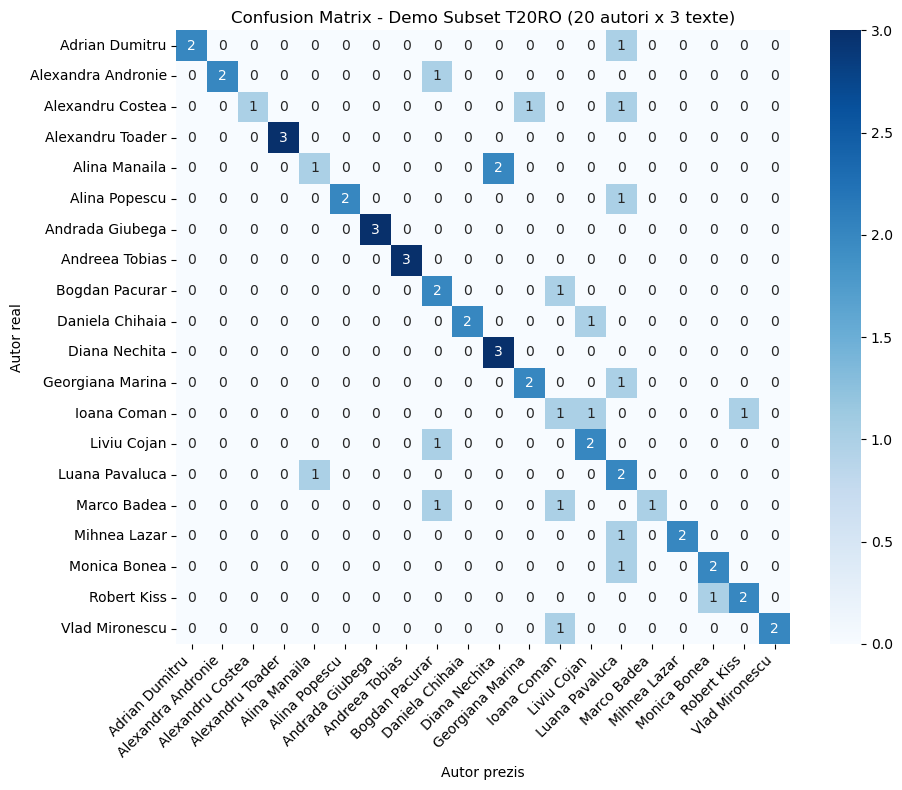

In [81]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

autori_selectati = [label_encoder_t20ro.classes_[i] 
                    for i in sorted(set(y_true_demo))]

cm = confusion_matrix(y_true_demo, y_pred_demo)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=autori_selectati,
    yticklabels=autori_selectati,
    square=True
)
plt.title('Confusion Matrix - Demo Subset T20RO (20 autori x 3 texte)')
plt.xlabel('Autor prezis')
plt.ylabel('Autor real')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

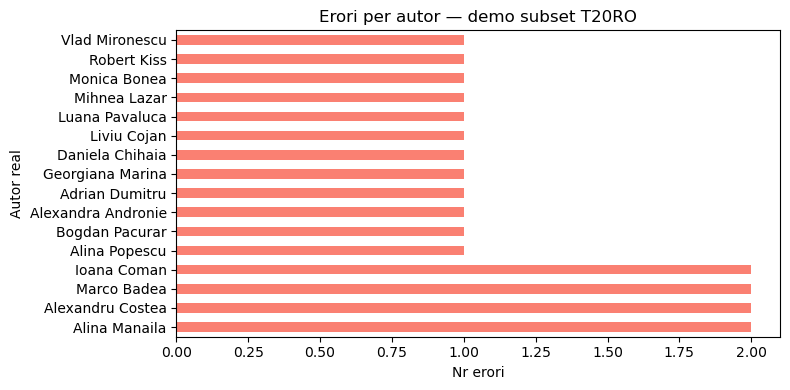

In [82]:
# ce autori au erori
erori_per_autor = df_results[df_results['Corect'] == '❌']['Autor real'].value_counts()
erori_per_autor.plot(kind='barh', color='salmon', figsize=(8,4))
plt.title('Erori per autor — demo subset T20RO')
plt.xlabel('Nr erori')
plt.tight_layout()
plt.show()

### Moldova top 20

In [82]:
# citim
top20_mo_train = pd.read_csv('final_stilo/top20_mo_train.csv')
top20_mo_val = pd.read_csv('final_stilo/top20_mo_val.csv')
top20_mo_test = pd.read_csv('final_stilo/top20_mo_test.csv')

In [83]:
model_path_baseline_mo20 = "outputs_transformer_baseline/top20_mo/best_model_top20_mo.pt"

In [84]:
# dataloadere
train_loader_t20mo, val_loader_t20mo, test_loader_t20mo, label_encoder_t20mo, texts_test_t20mo, y_test_t20mo = build_dataloaders_baseline(
    top20_mo_train, top20_mo_val, top20_mo_test,
    tokenizer)

Numar autori: 20
Autori: ['Aliona Ciurca' 'Ana-Maria Dolghii' 'Cristian Sava' 'Cristina Dulea'
 'Cristina Mirca' 'Cristina Popescu' 'Diana Gatcan' 'Diana Severin'
 'Ecaterina Arvintii' 'Malvina Cojocari' 'Marina Ciobanu' 'Maxim Stratan'
 'Mihaela Conovali' 'Milena Onisim' 'Nicoleta Braghis' 'Stela Untila'
 'Svetlana Cartin' 'Svetlana Cojocaru' 'Valentina Buza' 'Viorica Rusu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 343
Val   combining: 422
Test  combining: 366

[DEBUG] UNK check:
Train UNK: 43
Val   UNK: 33
Test  UNK: 53

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0


In [85]:
model_baseline = BaselineBERT(
    num_authors=len(label_encoder_t20mo.classes_)
).to(device)

model_baseline.load_state_dict(
    torch.load(model_path_baseline_mo20, map_location=device)
)
model_baseline.eval()
print("Baseline incarcat!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Baseline incarcat!


In [86]:
demo_indices = []
for autor in label_encoder_t20mo.classes_[:20]:  # primii 20 autori
    autor_idx = label_encoder_t20mo.transform([autor])[0]
    # gasim pozitiile din y_test unde apare autorul
    positions = [i for i, y in enumerate(y_test_t20mo) if y == autor_idx]
    demo_indices.extend(positions[:3])  # primele 3 texte

print(f"Texte demo: {len(demo_indices)}")

Texte demo: 60


In [87]:
# predictii
texts_demo  = [texts_test_t20mo[i] for i in demo_indices]
y_demo      = [y_test_t20mo[i]     for i in demo_indices]

results = []
for i, (text, true_label) in enumerate(zip(texts_demo, y_demo)):
    pred = predict_with_voting_baseline(
        model_baseline,
        text,
        tokenizer,    
        device=device   
    )
    results.append({
        'Autor real':   label_encoder_t20mo.classes_[true_label],
        'Autor prezis': label_encoder_t20mo.classes_[pred],
        'Corect':       '✅' if pred == true_label else '❌',
        'Text preview': text[:100] + '...'
    })
    print(f"  {i+1}/{len(texts_demo)}")

df_results = pd.DataFrame(results)
display(df_results)

  1/60
  2/60
  3/60
  4/60
  5/60
  6/60
  7/60
  8/60
  9/60
  10/60
  11/60
  12/60
  13/60
  14/60
  15/60
  16/60
  17/60
  18/60
  19/60
  20/60
  21/60
  22/60
  23/60
  24/60
  25/60
  26/60
  27/60
  28/60
  29/60
  30/60
  31/60
  32/60
  33/60
  34/60
  35/60
  36/60
  37/60
  38/60
  39/60
  40/60
  41/60
  42/60
  43/60
  44/60
  45/60
  46/60
  47/60
  48/60
  49/60
  50/60
  51/60
  52/60
  53/60
  54/60
  55/60
  56/60
  57/60
  58/60
  59/60
  60/60


,Autor real,Autor prezis,Corect,Text preview
0,Aliona Ciurca,Aliona Ciurca,✅,"Dumitru Braghiș, ambasadorul R. Moldova la Mos..."
1,Aliona Ciurca,Marina Ciobanu,❌,Trei polițiști din cadrul Direcției investigar...
2,Aliona Ciurca,Diana Gatcan,❌,Partidul Liberal (PL) urmează să prezinte o se...
3,Ana-Maria Dolghii,Ecaterina Arvintii,❌,"""Discutând despre stadiul procesului de negoci..."
4,Ana-Maria Dolghii,Ana-Maria Dolghii,✅,"Pe 2 iunie, la scurt timp după ce Canada a anu..."
5,Ana-Maria Dolghii,Malvina Cojocari,❌,Curtea de Apel Chișinău a respins argumentele ...
6,Cristian Sava,Cristian Sava,✅,"Conform proiectului, toate băncile din Republi..."
7,Cristian Sava,Stela Untila,❌,Schema infracțională de legalizare a construcț...
8,Cristian Sava,Cristian Sava,✅,"SA ""Apă-Canal Chișinău"" precizează că furnizar..."
9,Cristina Dulea,Diana Gatcan,❌,"Fritz von Weizsäcker, fiul fostului președinte..."


In [88]:
# erori
erori  = df_results[df_results['Corect'] == '❌']
corecte = df_results[df_results['Corect'] == '✅']

print(f"Corecte: {len(corecte)}/{len(df_results)}")
print(f"Erori:   {len(erori)}/{len(df_results)}")
print(f"Acuratete demo: {len(corecte)/len(df_results):.1%}")

display(erori[['Autor real', 'Autor prezis', 'Text preview']])

Corecte: 41/60
Erori:   19/60
Acuratete demo: 68.3%


,Autor real,Autor prezis,Text preview
1,Aliona Ciurca,Marina Ciobanu,Trei polițiști din cadrul Direcției investigar...
2,Aliona Ciurca,Diana Gatcan,Partidul Liberal (PL) urmează să prezinte o se...
3,Ana-Maria Dolghii,Ecaterina Arvintii,"""Discutând despre stadiul procesului de negoci..."
5,Ana-Maria Dolghii,Malvina Cojocari,Curtea de Apel Chișinău a respins argumentele ...
7,Cristian Sava,Stela Untila,Schema infracțională de legalizare a construcț...
9,Cristina Dulea,Diana Gatcan,"Fritz von Weizsäcker, fiul fostului președinte..."
12,Cristina Mirca,Stela Untila,Teal House este o comunitate cu focus pe dezvo...
15,Cristina Popescu,Cristian Sava,Ștefan Gligor spune că trecerea candidaților l...
16,Cristina Popescu,Svetlana Cojocaru,Acest program va ajuta ÎMM să-și sporească com...
17,Cristina Popescu,Cristina Mirca,IURIE CALESTRU director programe IDEP Moldova:...


In [90]:
# report
y_true_demo = y_demo
y_pred_demo = [label_encoder_t20mo.transform([r['Autor prezis']])[0] for r in results]

acc = accuracy_score(y_true_demo, y_pred_demo)
f1  = f1_score(y_true_demo, y_pred_demo, average='macro')

print(f"Accuracy demo:  {acc:.2%}")
print(f"F1 Macro demo:  {f1:.4f}")
print()
print(classification_report(
    y_true_demo, y_pred_demo,
    target_names=label_encoder_t20mo.classes_[:20],
    zero_division=0
))

Accuracy demo:  68.33%
F1 Macro demo:  0.6680

                    precision    recall  f1-score   support

     Aliona Ciurca       1.00      0.33      0.50         3
 Ana-Maria Dolghii       1.00      0.33      0.50         3
     Cristian Sava       0.40      0.67      0.50         3
    Cristina Dulea       0.50      0.67      0.57         3
    Cristina Mirca       0.50      0.67      0.57         3
  Cristina Popescu       0.00      0.00      0.00         3
      Diana Gatcan       0.60      1.00      0.75         3
     Diana Severin       1.00      0.67      0.80         3
Ecaterina Arvintii       0.60      1.00      0.75         3
  Malvina Cojocari       0.50      0.33      0.40         3
    Marina Ciobanu       0.67      0.67      0.67         3
     Maxim Stratan       1.00      1.00      1.00         3
  Mihaela Conovali       1.00      0.67      0.80         3
     Milena Onisim       1.00      1.00      1.00         3
  Nicoleta Braghis       1.00      1.00      1.00   

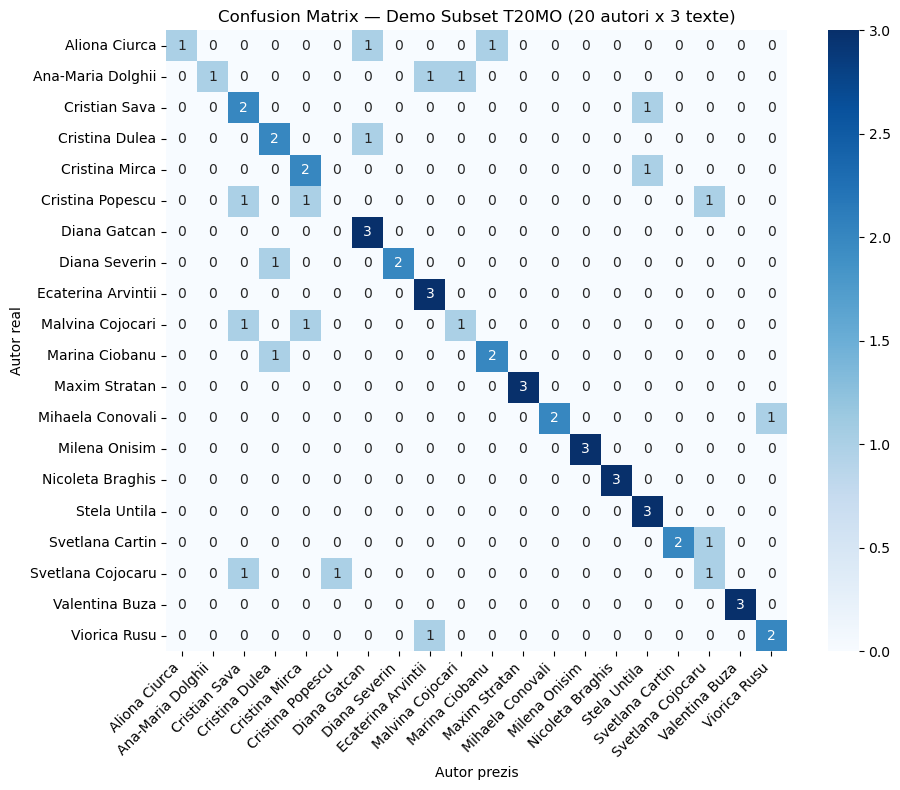

In [92]:
# confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

autori_selectati = [label_encoder_t20mo.classes_[i] 
                    for i in sorted(set(y_true_demo))]

cm = confusion_matrix(y_true_demo, y_pred_demo)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=autori_selectati,
    yticklabels=autori_selectati,
    square=True
)

plt.title('Confusion Matrix — Demo Subset T20MO (20 autori x 3 texte)')
plt.xlabel('Autor prezis')
plt.ylabel('Autor real')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

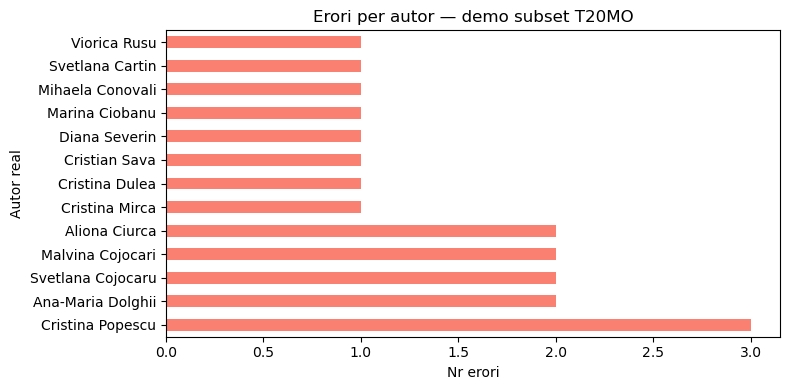

In [93]:
# distributia erorilor
erori_per_autor = df_results[df_results['Corect'] == '❌']['Autor real'].value_counts()
erori_per_autor.plot(kind='barh', color='salmon', figsize=(8,4))
plt.title('Erori per autor — demo subset T20MO')
plt.xlabel('Nr erori')
plt.tight_layout()
plt.show()